In [1]:
# Import Pandas for data loading, cleaning, manipulation, and analysis

# Import NumPy for numerical calculations and array operations

# Import Matplotlib for data visualization and creating charts

In [413]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [415]:
# Load the Customers dataset using Latin-1 encoding to handle special characters
customers = pd.read_csv("../Customers.csv", encoding="latin1")

In [417]:
# Preview the top 5 rows of the data
customers.head()

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,7/3/1939
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,9/27/1979
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,5/26/1947
3,786,Male,Jai Poltpalingada,MIDDLE RIVER,SA,South Australia,5223,Australia,Australia,9/17/1957
4,1042,Male,Aidan Pankhurst,TAWONGA SOUTH,VIC,Victoria,3698,Australia,Australia,11/19/1965


In [419]:
# Retail Sales Analytics

## 1. Data Loading and Validation

### Customers Dataset
#The customer dataset contains 15,266 records. Initial validation was performed to check data types and missing values.

In [421]:
# Load customers data

In [423]:
customers.shape

(15266, 10)

In [425]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15266 entries, 0 to 15265
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CustomerKey  15266 non-null  int64 
 1   Gender       15266 non-null  object
 2   Name         15266 non-null  object
 3   City         15266 non-null  object
 4   State Code   15256 non-null  object
 5   State        15266 non-null  object
 6   Zip Code     15266 non-null  object
 7   Country      15266 non-null  object
 8   Continent    15266 non-null  object
 9   Birthday     15266 non-null  object
dtypes: int64(1), object(9)
memory usage: 1.2+ MB


In [427]:
customers.isnull().sum()

CustomerKey     0
Gender          0
Name            0
City            0
State Code     10
State           0
Zip Code        0
Country         0
Continent       0
Birthday        0
dtype: int64

In [429]:
customers[customers["State Code"].isnull()]

,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
5304,729681,Female,Rossana Padovesi,Polvica,NaN,Napoli,80035,Italy,Europe,4/18/1981
5316,732289,Male,Indro Piccio,Varcaturo,NaN,Napoli,80014,Italy,Europe,2/24/1949
5372,742042,Male,Amaranto Loggia,Casaferro,NaN,Napoli,80034,Italy,Europe,3/14/1936
5377,742886,Female,Edmonda Capon,Terzigno,NaN,Napoli,80040,Italy,Europe,8/6/1963
5378,743343,Female,Ambra Sagese,Pomigliano D'Arco,NaN,Napoli,80038,Italy,Europe,1/5/1961
5485,759705,Male,Callisto Lo Duca,Casilli,NaN,Napoli,80047,Italy,Europe,8/28/1976
5525,765589,Male,Michelino Lucchesi,Pompei Scavi,NaN,Napoli,80045,Italy,Europe,11/13/1947
5531,766410,Male,Adelmio Beneventi,Licola,NaN,Napoli,80078,Italy,Europe,1/13/1940
5631,781667,Female,Ilda Manna,Napoli,NaN,Napoli,80134,Italy,Europe,5/8/1977
5695,789177,Male,Calogero Folliero,Mariglianella,NaN,Napoli,80030,Italy,Europe,3/3/2000


In [431]:
customers.loc[
    customers["State Code"].isnull(),
    ["City", "State Code", "State", "Country"]
]

,City,State Code,State,Country
5304,Polvica,NaN,Napoli,Italy
5316,Varcaturo,NaN,Napoli,Italy
5372,Casaferro,NaN,Napoli,Italy
5377,Terzigno,NaN,Napoli,Italy
5378,Pomigliano D'Arco,NaN,Napoli,Italy
5485,Casilli,NaN,Napoli,Italy
5525,Pompei Scavi,NaN,Napoli,Italy
5531,Licola,NaN,Napoli,Italy
5631,Napoli,NaN,Napoli,Italy
5695,Mariglianella,NaN,Napoli,Italy


In [433]:
customers["Birthday"] = pd.to_datetime(customers["Birthday"])

In [435]:
# Load the products dataset
products = pd.read_csv("../Products.csv")

In [437]:
# Display the first 5 rows
products.head()

,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,1,Contoso 512MB MP3 Player E51 Silver,Contoso,Silver,$6.62,$12.99,101,MP4&MP3,1,Audio
1,2,Contoso 512MB MP3 Player E51 Blue,Contoso,Blue,$6.62,$12.99,101,MP4&MP3,1,Audio
2,3,Contoso 1G MP3 Player E100 White,Contoso,White,$7.40,$14.52,101,MP4&MP3,1,Audio
3,4,Contoso 2G MP3 Player E200 Silver,Contoso,Silver,$11.00,$21.57,101,MP4&MP3,1,Audio
4,5,Contoso 2G MP3 Player E200 Red,Contoso,Red,$11.00,$21.57,101,MP4&MP3,1,Audio


In [439]:
from pathlib import Path

files = [
    "Customers.csv",
    "Products.csv",
    "Sales.csv",
    "Stores.csv",
    "Exchange_Rates.csv",
    "Data_Dictionary.csv"
]

for file in files:
    print(file, ":", Path("..", file).exists())

Customers.csv : True
Products.csv : True
Sales.csv : True
Stores.csv : True
Exchange_Rates.csv : True
Data_Dictionary.csv : True


In [441]:
# Check number of rows and columns
products.shape

(2517, 10)

In [443]:
products.info();

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2517 entries, 0 to 2516
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ProductKey      2517 non-null   int64 
 1   Product Name    2517 non-null   object
 2   Brand           2517 non-null   object
 3   Color           2517 non-null   object
 4   Unit Cost USD   2517 non-null   object
 5   Unit Price USD  2517 non-null   object
 6   SubcategoryKey  2517 non-null   int64 
 7   Subcategory     2517 non-null   object
 8   CategoryKey     2517 non-null   int64 
 9   Category        2517 non-null   object
dtypes: int64(3), object(7)
memory usage: 196.8+ KB


In [445]:
# Check for missing values in each product column
products.isnull().sum()

ProductKey        0
Product Name      0
Brand             0
Color             0
Unit Cost USD     0
Unit Price USD    0
SubcategoryKey    0
Subcategory       0
CategoryKey       0
Category          0
dtype: int64

In [447]:
# Inspect the original currency-formatted price columns
products[["Unit Cost USD", "Unit Price USD"]].head()

,Unit Cost USD,Unit Price USD
0,$6.62,$12.99
1,$6.62,$12.99
2,$7.40,$14.52
3,$11.00,$21.57
4,$11.00,$21.57


In [449]:
# Remove currency symbols and commas from product cost and price
products["Unit Cost USD"] = products["Unit Cost USD"].str.replace("$", "", regex=False).str.replace(",", "", regex=False)

products["Unit Price USD"] = products["Unit Price USD"].str.replace("$", "", regex=False).str.replace(",", "", regex=False)

In [451]:
# Convert cleaned cost and price columns from text to numeric
products["Unit Cost USD"] = pd.to_numeric(products["Unit Cost USD"])

products["Unit Price USD"] = pd.to_numeric(products["Unit Price USD"])

In [453]:
products[["Unit Cost USD", "Unit Price USD"]].head()

,Unit Cost USD,Unit Price USD
0,6.62,12.99
1,6.62,12.99
2,7.40,14.52
3,11.00,21.57
4,11.00,21.57


In [455]:
products[["Unit Cost USD", "Unit Price USD"]].dtypes

Unit Cost USD     float64
Unit Price USD    float64
dtype: object

In [457]:
# Check for products where selling price is lower than cost
products[products["Unit Price USD"] < products["Unit Cost USD"]]

,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category


In [459]:
# Confirm the number of product records
products.shape

(2517, 10)

In [461]:
# Load the Sales dataset
sales = pd.read_csv("../Sales.csv")

In [463]:
# Preview the first 5 sales records
sales.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD
3,366002,1,1/1/2016,1/12/2016,266019,0,1106,7,CAD
4,366002,2,1/1/2016,1/12/2016,266019,0,373,1,CAD


In [465]:
# Check the number of rows and columns
sales.shape

(62884, 9)

In [467]:
# Check column names, data types, and non-null counts
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Order Number   62884 non-null  int64 
 1   Line Item      62884 non-null  int64 
 2   Order Date     62884 non-null  object
 3   Delivery Date  13165 non-null  object
 4   CustomerKey    62884 non-null  int64 
 5   StoreKey       62884 non-null  int64 
 6   ProductKey     62884 non-null  int64 
 7   Quantity       62884 non-null  int64 
 8   Currency Code  62884 non-null  object
dtypes: int64(6), object(3)
memory usage: 4.3+ MB


In [469]:
# Convert order and delivery dates from text to datetime
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Delivery Date"] = pd.to_datetime(sales["Delivery Date"])

In [471]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62884 entries, 0 to 62883
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order Number   62884 non-null  int64         
 1   Line Item      62884 non-null  int64         
 2   Order Date     62884 non-null  datetime64[ns]
 3   Delivery Date  13165 non-null  datetime64[ns]
 4   CustomerKey    62884 non-null  int64         
 5   StoreKey       62884 non-null  int64         
 6   ProductKey     62884 non-null  int64         
 7   Quantity       62884 non-null  int64         
 8   Currency Code  62884 non-null  object        
dtypes: datetime64[ns](2), int64(6), object(1)
memory usage: 4.3+ MB


In [473]:
sales.isnull().sum()

Order Number         0
Line Item            0
Order Date           0
Delivery Date    49719
CustomerKey          0
StoreKey             0
ProductKey           0
Quantity             0
Currency Code        0
dtype: int64

In [475]:
# Check for duplicate Order Number + Line Item combinations
sales.duplicated(
    subset=["Order Number", "Line Item"]
).sum()

0

In [477]:
# Check for zero or missing quantities
sales[
    (sales["Quantity"] == 0) |
    (sales["Quantity"].isnull())
]

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code


In [479]:
# Check for negative quantities
sales[sales["Quantity"] < 0]

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code


In [481]:
# Find sales records with CustomerKeys not found in the Customers dataset-(~ means NOT)
sales[~sales["CustomerKey"].isin(customers["CustomerKey"])]

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code


In [483]:
sales["CustomerKey"].isin(customers["CustomerKey"])

0        True
1        True
2        True
3        True
4        True
         ... 
62879    True
62880    True
62881    True
62882    True
62883    True
Name: CustomerKey, Length: 62884, dtype: bool

In [485]:
# Show sales records whose ProductKey does NOT exist in Products
sales[~sales["ProductKey"].isin(products["ProductKey"])]

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code


In [487]:
# Load the Stores dataset
stores = pd.read_csv("../Stores.csv")

In [489]:
stores.head()

,StoreKey,Country,State,Square Meters,Open Date
0,1,Australia,Australian Capital Territory,595.0,1/1/2008
1,2,Australia,Northern Territory,665.0,1/12/2008
2,3,Australia,South Australia,2000.0,1/7/2012
3,4,Australia,Tasmania,2000.0,1/1/2010
4,5,Australia,Victoria,2000.0,12/9/2015


In [491]:
stores.shape

(67, 5)

In [493]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   StoreKey       67 non-null     int64  
 1   Country        67 non-null     object 
 2   State          67 non-null     object 
 3   Square Meters  66 non-null     float64
 4   Open Date      67 non-null     object 
dtypes: float64(1), int64(1), object(3)
memory usage: 2.7+ KB


In [495]:
# Check the store record with missing Square Meters
stores[stores["Square Meters"].isnull()]

,StoreKey,Country,State,Square Meters,Open Date
66,0,Online,Online,NaN,1/1/2010


In [497]:
# Convert Open Date from text to datetime
stores["Open Date"] = pd.to_datetime(stores["Open Date"])

In [499]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   StoreKey       67 non-null     int64         
 1   Country        67 non-null     object        
 2   State          67 non-null     object        
 3   Square Meters  66 non-null     float64       
 4   Open Date      67 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 2.7+ KB


In [501]:
# Load the Exchange Rates dataset
exchange_rates = pd.read_csv("../Exchange_Rates.csv")

In [503]:
exchange_rates.head()

,Date,Currency,Exchange
0,1/1/2015,USD,1.0000
1,1/1/2015,CAD,1.1583
2,1/1/2015,AUD,1.2214
3,1/1/2015,EUR,0.8237
4,1/1/2015,GBP,0.6415


In [505]:
exchange_rates.shape

(11215, 3)

In [507]:
exchange_rates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11215 entries, 0 to 11214
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      11215 non-null  object 
 1   Currency  11215 non-null  object 
 2   Exchange  11215 non-null  float64
dtypes: float64(1), object(2)
memory usage: 263.0+ KB


In [509]:
exchange_rates["Date"] = pd.to_datetime(exchange_rates["Date"])

In [511]:
exchange_rates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11215 entries, 0 to 11214
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      11215 non-null  datetime64[ns]
 1   Currency  11215 non-null  object        
 2   Exchange  11215 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 263.0+ KB


In [513]:
# Check for duplicate Date + Currency combinations
exchange_rates.duplicated(
    subset=["Date", "Currency"]
).sum()

0

In [515]:
# Merge Sales with Products using ProductKey
sales_analysis = sales.merge(
    products,
    on="ProductKey",
    how="left"
)
sales_analysis.shape

(62884, 18)

In [517]:
# Merge customer information into the analysis dataset
sales_analysis = sales_analysis.merge(
    customers,
    on="CustomerKey",
    how="left"
)

sales_analysis.shape

(62884, 27)

In [519]:
sales_analysis.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,...,Category,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,366000,1,2016-01-01,NaT,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,...,Cameras and camcorders,Male,Tyler Vaught,London,ON,Ontario,N5W 5K6,Canada,North America,1971-03-23
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,...,Cameras and camcorders,Male,Frank Upchurch,Auberry,CA,California,93602,United States,North America,1995-11-20
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,...,Home Appliances,Male,Frank Upchurch,Auberry,CA,California,93602,United States,North America,1995-11-20
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,...,Cameras and camcorders,Female,Joan Roche,Red Deer,AB,Alberta,T4N 2A6,Canada,North America,1962-08-24
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,...,Computers,Female,Joan Roche,Red Deer,AB,Alberta,T4N 2A6,Canada,North America,1962-08-24


In [521]:
# Check for unmatched customers after the merge
sales_analysis["Name"].isnull().sum()

0

In [523]:
# Merge store information into the analysis dataset
sales_analysis = sales_analysis.merge(
    stores,
    on="StoreKey",
    how="left"
)

In [525]:
# Rename overlapping customer and store location columns
# to clearly distinguish customer and store information

sales_analysis = sales_analysis.rename(columns={
    "Country_x": "Customer Country",
    "State_x": "Customer State",
    "Country_y": "Store Country",
    "State_y": "Store State"
})

In [527]:
sales_analysis.shape

(62884, 31)

In [529]:
# TEMPORARY CHECK — Delete after verification
# Identify store-related columns after the merge

print(sales_analysis.columns.tolist())

['Order Number', 'Line Item', 'Order Date', 'Delivery Date', 'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code', 'Product Name', 'Brand', 'Color', 'Unit Cost USD', 'Unit Price USD', 'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category', 'Gender', 'Name', 'City', 'State Code', 'Customer State', 'Zip Code', 'Customer Country', 'Continent', 'Birthday', 'Store Country', 'Store State', 'Square Meters', 'Open Date']


In [531]:
# TEMPORARY CHECK — Delete after verification
# Verify store information after merging

print("Shape:", sales_analysis.shape)
print("Missing store countries:", sales_analysis["Store Country"].isna().sum())

Shape: (62884, 31)
Missing store countries: 0


In [533]:
# Check for unmatched StoreKeys after the merge
sales_analysis["Open Date"].isnull().sum()

0

In [535]:
# Display all column names in the merged analysis dataset
sales_analysis.columns

Index(['Order Number', 'Line Item', 'Order Date', 'Delivery Date',
       'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code',
       'Product Name', 'Brand', 'Color', 'Unit Cost USD', 'Unit Price USD',
       'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category', 'Gender',
       'Name', 'City', 'State Code', 'Customer State', 'Zip Code',
       'Customer Country', 'Continent', 'Birthday', 'Store Country',
       'Store State', 'Square Meters', 'Open Date'],
      dtype='object')

In [537]:
# Convert Unit Price USD from currency text to numeric values
sales_analysis["Unit Price USD"] = pd.to_numeric(
    sales_analysis["Unit Price USD"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

In [539]:
# Calculate revenue for each sales line
sales_analysis["Revenue USD"] = (
    sales_analysis["Quantity"] * sales_analysis["Unit Price USD"]
)

In [541]:
# Validate Total Revenue
print("Total Revenue:", round(sales_analysis["Revenue USD"].sum(), 2))

Total Revenue: 55755479.59


In [543]:
# Calculate total cost for each sales line
# Clean Unit Cost USD by removing $ and commas
sales_analysis["Unit Cost USD"] = pd.to_numeric(
    sales_analysis["Unit Cost USD"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

# Calculate total cost for each sales line
sales_analysis["Cost USD"] = (
    sales_analysis["Quantity"] * sales_analysis["Unit Cost USD"]
)

In [545]:
# Calculate gross profit for each sales line
sales_analysis["Gross Profit USD"] = (
    sales_analysis["Revenue USD"] - sales_analysis["Cost USD"]
)

In [547]:
print("Missing Cost:", sales_analysis["Cost USD"].isna().sum())

Missing Cost: 0


In [549]:
# Calculate gross profit for each sales line
sales_analysis["Gross Profit USD"] = (
    sales_analysis["Revenue USD"] - sales_analysis["Cost USD"]
)

In [551]:
# Calculate overall financial KPIs
total_revenue = sales_analysis["Revenue USD"].sum()
total_cost = sales_analysis["Cost USD"].sum()
total_gross_profit = sales_analysis["Gross Profit USD"].sum()

print("Total Revenue:", round(total_revenue, 2))
print("Total Cost:", round(total_cost, 2))
print("Gross Profit:", round(total_gross_profit, 2))

Total Revenue: 55755479.59
Total Cost: 23092791.21
Gross Profit: 32662688.38


In [553]:
# Calculate overall gross profit margin
gross_profit_margin = (
    total_gross_profit / total_revenue
) * 100

print("Gross Profit Margin:", round(gross_profit_margin, 2), "%")

Gross Profit Margin: 58.58 %


In [555]:
# Calculate total revenue generated by each customer
customer_revenue = (
    sales_analysis
    .groupby(["CustomerKey", "Name"], as_index=False)
    ["Revenue USD"]
    .sum()
)

In [557]:
customer_revenue.head()

,CustomerKey,Name,Revenue USD
0,301,Lilly Harding,592.00
1,325,Madison Hull,5787.67
2,554,Claire Ferres,951.71
3,1042,Aidan Pankhurst,1124.91
4,1314,Isaac Israel,2539.86


In [559]:
customer_revenue.shape

(11887, 3)

In [561]:
# Summary statistics for customer revenue
customer_revenue["Revenue USD"].describe()

count    11887.000000
mean      4690.458450
std       5197.622706
min          1.990000
25%       1138.915000
50%       2995.000000
75%       6425.065000
max      61871.700000
Name: Revenue USD, dtype: float64

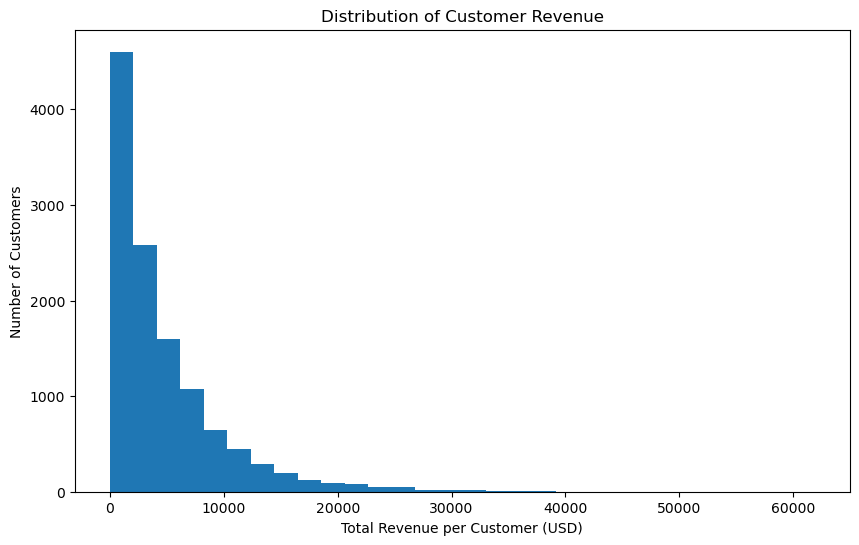

In [563]:
# Visualize the distribution of total revenue per customer-histogram

plt.figure(figsize=(10, 6))

plt.hist(customer_revenue["Revenue USD"], bins=30)

plt.title("Distribution of Customer Revenue")
plt.xlabel("Total Revenue per Customer (USD)")
plt.ylabel("Number of Customers")

plt.show()

In [565]:
# Sort customers by revenue from highest to lowest
customer_revenue_sorted = customer_revenue.sort_values(
    "Revenue USD",
    ascending=False
)

In [567]:
# Calculate the number of customers in the top 20%
top_20_count = int(len(customer_revenue_sorted) * 0.20)

top_20_count

2377

In [569]:
print("Revenue sample:")
print(sales_analysis["Revenue USD"].head(10))

print("Revenue total:")
print(sales_analysis["Revenue USD"].sum())

print("Revenue minimum and maximum:")
print(sales_analysis["Revenue USD"].min())
print(sales_analysis["Revenue USD"].max())

Revenue sample:
0      68.00
1     854.00
2     665.94
3    2254.00
4     326.00
5    2584.00
6    9553.20
7     510.00
8    1876.00
9      57.99
Name: Revenue USD, dtype: float64
Revenue total:
55755479.589999996
Revenue minimum and maximum:
0.95
31999.899999999998


In [571]:
# Calculate revenue generated by the top 20% of customers
top_20_revenue = customer_revenue_sorted.head(top_20_count)["Revenue USD"].sum()

top_20_revenue

30852376.49

In [573]:
print(customer_revenue_sorted.head())

       CustomerKey               Name  Revenue USD
9371       1702221   Matthew Flemming     61871.70
10515      1884663        Karen Jones     43517.80
11072      1969704        Zrina Topic     42788.04
2743        535496  Stefanie Hartmann     41521.53
2840        551036  Stephan Rothstein     40556.54


In [575]:
print(customer_revenue_sorted[["Revenue USD"]].head(10))
print("Total Customer Revenue:", customer_revenue_sorted["Revenue USD"].sum())

       Revenue USD
9371      61871.70
10515     43517.80
11072     42788.04
2743      41521.53
2840      40556.54
3664      40225.01
1175      38813.88
10795     38191.06
8116      37319.88
7275      36817.28
Total Customer Revenue: 55755479.58999999


In [577]:
# Calculate the percentage of total revenue generated by the top 20% of customers
top_20_revenue_pct = (
    top_20_revenue / total_revenue
) * 100

round(top_20_revenue_pct, 2)

55.34

In [579]:
# Calculate cumulative revenue contribution
customer_revenue_sorted["Cumulative Revenue"] = (
    customer_revenue_sorted["Revenue USD"].cumsum()
)

customer_revenue_sorted["Cumulative Revenue %"] = (
    customer_revenue_sorted["Cumulative Revenue"] / total_revenue
) * 100

In [581]:
# Calculate cumulative percentage of customers
import numpy as np
customer_revenue_sorted["Customer %"] = (
    np.arange(1, len(customer_revenue_sorted) + 1)
    / len(customer_revenue_sorted)
) * 100

In [583]:
customer_revenue_sorted.head()

,CustomerKey,Name,Revenue USD,Cumulative Revenue,Cumulative Revenue %,Customer %
9371,1702221,Matthew Flemming,61871.70,61871.70,0.110970,0.008413
10515,1884663,Karen Jones,43517.80,105389.50,0.189021,0.016825
11072,1969704,Zrina Topic,42788.04,148177.54,0.265763,0.025238
2743,535496,Stefanie Hartmann,41521.53,189699.07,0.340234,0.033650
2840,551036,Stephan Rothstein,40556.54,230255.61,0.412974,0.042063


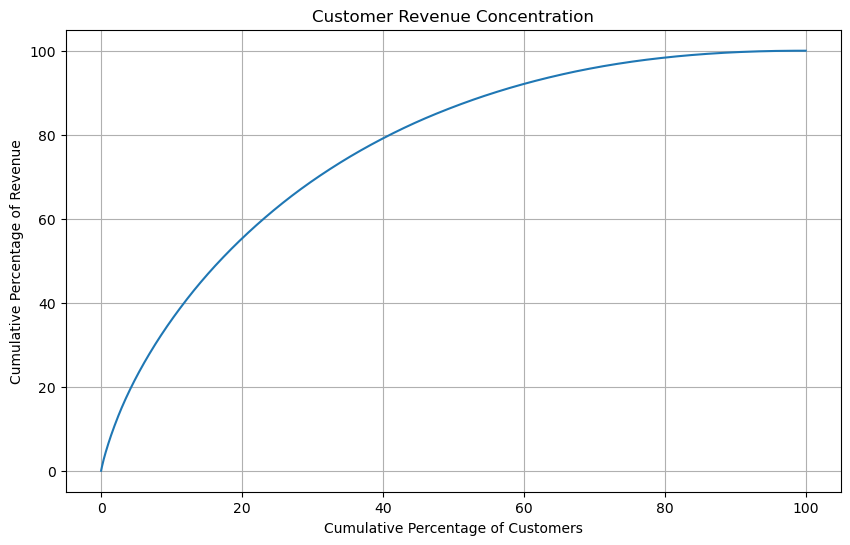

In [585]:
# Plot cumulative customer percentage vs cumulative revenue percentage
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

plt.plot(
    customer_revenue_sorted["Customer %"],
    customer_revenue_sorted["Cumulative Revenue %"]
)

plt.xlabel("Cumulative Percentage of Customers")
plt.ylabel("Cumulative Percentage of Revenue")
plt.title("Customer Revenue Concentration")

plt.grid(True)
plt.show()

In [587]:
#How many distinct orders does each purchasing customer place?
#one Order Number can contain multiple Line Items(we count unique Order Numbers, not rows).
customer_orders = (
    sales_analysis
    .groupby(["CustomerKey", "Name"])["Order Number"]
    .nunique()
    .reset_index(name="Number of Orders")
)

customer_orders.head()

,CustomerKey,Name,Number of Orders
0,301,Lilly Harding,1
1,325,Madison Hull,3
2,554,Claire Ferres,2
3,1042,Aidan Pankhurst,1
4,1314,Isaac Israel,1


In [589]:
customer_orders["Number of Orders"].describe()

count    11887.000000
mean         2.214688
std          1.391487
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         14.000000
Name: Number of Orders, dtype: float64

In [591]:
# Count one-time and repeat customers
one_time_customers = (customer_orders["Number of Orders"] == 1).sum()

repeat_customers = (customer_orders["Number of Orders"] > 1).sum()

one_time_customers, repeat_customers

(4615, 7272)

In [593]:
# Calculate the percentages:
total_purchasing_customers = len(customer_orders)

one_time_pct = (one_time_customers / total_purchasing_customers) * 100
repeat_pct = (repeat_customers / total_purchasing_customers) * 100

round(one_time_pct, 2), round(repeat_pct, 2)

(38.82, 61.18)

In [595]:
#do repeat customers generate more revenue?
customer_behavior = customer_revenue.merge(
    customer_orders,
    on=["CustomerKey", "Name"]
)

customer_behavior.head()

,CustomerKey,Name,Revenue USD,Number of Orders
0,301,Lilly Harding,592.00,1
1,325,Madison Hull,5787.67,3
2,554,Claire Ferres,951.71,2
3,1042,Aidan Pankhurst,1124.91,1
4,1314,Isaac Israel,2539.86,1


In [597]:
customer_behavior["Customer Type"] = np.where(
    customer_behavior["Number of Orders"] == 1,
    "One-time",
    "Repeat"
)

In [599]:
customer_behavior.groupby("Customer Type")["Revenue USD"].agg(
    ["count", "sum", "mean", "median"]
)

,count,sum,mean,median
Customer Type,,,,
One-time,4615,9819402.20,2127.714453,1179.0
Repeat,7272,45936077.39,6316.842325,4663.9


In [601]:
repeat_revenue_pct = (
    45936077.39 / total_revenue
) * 100

round(repeat_revenue_pct, 2)

82.39

In [603]:
#Average Order Value = Revenue ÷ Number of Orders
customer_behavior["AOV"] = (
    customer_behavior["Revenue USD"]
    / customer_behavior["Number of Orders"]
)

In [605]:
customer_behavior.groupby("Customer Type")["AOV"].agg(
    ["mean", "median"]
)

,mean,median
Customer Type,,
One-time,2127.714453,1179.000
Repeat,2119.121171,1636.495


In [607]:
#the above output shows clearly that our earlier finding that repeat customers generate almost 3× more revenue per customer is not because their average order is much larger.
#It's mainly because they place more orders.

In [609]:
#Category performance
category_performance = (
    sales_analysis
    .groupby("Category")
    .agg({
        "Revenue USD": "sum",
        "Cost USD": "sum",
        "Gross Profit USD": "sum"
    })
    .reset_index()
)

In [611]:
category_performance["Gross Margin %"] = (
    category_performance["Gross Profit USD"]
    / category_performance["Revenue USD"]
) * 100

In [613]:
# Sort product categories by total revenue (highest first)
category_performance = category_performance.sort_values(
    "Revenue USD",
    ascending=False
)

category_performance.round(2)

,Category,Revenue USD,Cost USD,Gross Profit USD,Gross Margin %
3,Computers,19301595.46,8024147.56,11277447.90,58.43
5,Home Appliances,10795478.59,4499139.74,6296338.85,58.32
1,Cameras and camcorders,6520168.02,2600367.03,3919800.99,60.12
2,Cell phones,6183791.22,2685164.68,3498626.54,56.58
7,TV and Video,5928982.69,2392288.30,3536694.39,59.65
0,Audio,3169627.74,1341775.97,1827851.77,57.67
6,"Music, Movies and Audio Books",3131006.44,1221747.27,1909259.17,60.98
4,Games and Toys,724829.43,328160.66,396668.77,54.73


In [615]:
category_performance = (
    sales_analysis
    .groupby("Category")
    .agg({
        "Revenue USD": "sum",
        "Cost USD": "sum",
        "Gross Profit USD": "sum"
    })
    .reset_index()
)
category_performance["Gross Margin %"] = (
    category_performance["Gross Profit USD"]
    / category_performance["Revenue USD"]
) * 100
category_performance = category_performance.sort_values(
    "Revenue USD",
    ascending=False
)

category_performance.round(2)

,Category,Revenue USD,Cost USD,Gross Profit USD,Gross Margin %
3,Computers,19301595.46,8024147.56,11277447.90,58.43
5,Home Appliances,10795478.59,4499139.74,6296338.85,58.32
1,Cameras and camcorders,6520168.02,2600367.03,3919800.99,60.12
2,Cell phones,6183791.22,2685164.68,3498626.54,56.58
7,TV and Video,5928982.69,2392288.30,3536694.39,59.65
0,Audio,3169627.74,1341775.97,1827851.77,57.67
6,"Music, Movies and Audio Books",3131006.44,1221747.27,1909259.17,60.98
4,Games and Toys,724829.43,328160.66,396668.77,54.73


In [617]:
#product's percentage contribution to its category revenue
product_performance = (
    sales_analysis
    .groupby(["Category", "ProductKey", "Product Name"], as_index=False)
    .agg({
        "Revenue USD": "sum",
        "Gross Profit USD": "sum",
        "Quantity": "sum"
    })
)

product_performance.head()

,Category,ProductKey,Product Name,Revenue USD,Gross Profit USD,Quantity
0,Audio,1,Contoso 512MB MP3 Player E51 Silver,844.35,414.05,65
1,Audio,2,Contoso 512MB MP3 Player E51 Blue,1000.23,490.49,77
2,Audio,3,Contoso 1G MP3 Player E100 White,1161.60,569.60,80
3,Audio,4,Contoso 2G MP3 Player E200 Silver,1596.18,782.18,74
4,Audio,5,Contoso 2G MP3 Player E200 Red,1056.93,517.93,49


In [619]:
#Product contribution within each category

In [621]:
# total revenue for each category
product_performance["Category Revenue"] = (
    product_performance
    .groupby("Category")["Revenue USD"]
    .transform("sum")
)

In [623]:
# each product's contribution to its category revenue
product_performance["Category Revenue %"] = (
    product_performance["Revenue USD"]
    / product_performance["Category Revenue"]
) * 100

In [625]:
#top revenue-generating product within each category:
top_product_by_category = (
    product_performance
    .sort_values("Revenue USD", ascending=False)
    .groupby("Category")
    .head(1)
)

top_product_by_category[
    ["Category", "Product Name", "Revenue USD", "Category Revenue %"]
].round(2)

,Category,Product Name,Revenue USD,Category Revenue %
878,Computers,WWI Desktop PC2.33 X2330 Black,505450.00,2.62
2302,TV and Video,"Adventure Works 52"" LCD HDTV X590 White",394398.64,6.65
1816,Home Appliances,Contoso Water Heater 7.2GPM X1800 Silver,231575.00,2.15
377,Cameras and camcorders,Fabrikam Independent Filmmaker 1/3'' 8.5mm X20...,132600.00,2.03
614,Cell phones,The Phone Company Touch Screen Phone 1600 TFT-...,118389.00,1.91
55,Audio,WWI 4GB Video Recording Pen X200 Yellow,109520.00,3.46
2219,"Music, Movies and Audio Books",SV DVD 14-Inch Player Portable L100 Silver,101656.09,3.25
1482,Games and Toys,MGS Age of Empires Expansion: The Rise of Rome...,48502.80,6.69


In [627]:
# Clean product prices before merging
products["Unit Price USD"] = pd.to_numeric(
    products["Unit Price USD"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

In [629]:
#Product price vs sales volume
#Do lower-priced products tend to sell more units?

product_performance = product_performance.merge(
    products[["ProductKey", "Unit Price USD"]],
    on="ProductKey",
    how="left"
)

In [631]:
product_performance[
    ["Product Name", "Unit Price USD", "Quantity"]
].head()

,Product Name,Unit Price USD,Quantity
0,Contoso 512MB MP3 Player E51 Silver,12.99,65
1,Contoso 512MB MP3 Player E51 Blue,12.99,77
2,Contoso 1G MP3 Player E100 White,14.52,80
3,Contoso 2G MP3 Player E200 Silver,21.57,74
4,Contoso 2G MP3 Player E200 Red,21.57,49


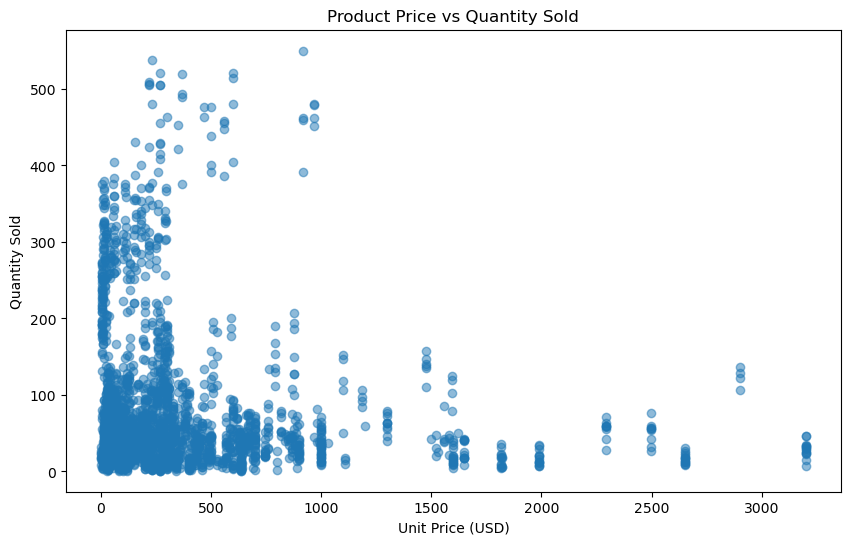

In [633]:
#Price vs. Quantity Sold
#Is product price associated with sales volume?

plt.figure(figsize=(10, 6))
plt.scatter(
    product_performance["Unit Price USD"],
    product_performance["Quantity"],
    alpha=0.5
)

plt.title("Product Price vs Quantity Sold")
plt.xlabel("Unit Price (USD)")
plt.ylabel("Quantity Sold")

plt.show()

In [635]:
# Correlation between unit price and quantity sold
correlation = product_performance["Unit Price USD"].corr(
    product_performance["Quantity"]
)

correlation

-0.1290995857767058

In [637]:
# Monthly Revenue Trend

# Convert Order Date to datetime
sales_analysis["Order Date"] = pd.to_datetime(
    sales_analysis["Order Date"]
)

# Create Year-Month column
sales_analysis["Year-Month"] = (
    sales_analysis["Order Date"].dt.to_period("M")
)

In [639]:
#Monthly Revenue Trend.
#Create month column.-rder Date is already datetime

sales_analysis["Year-Month"] = (
    sales_analysis["Order Date"]
    .dt.to_period("M")
)

In [641]:
print(sales_analysis[["Order Date", "Year-Month"]].head())

  Order Date Year-Month
0 2016-01-01    2016-01
1 2016-01-01    2016-01
2 2016-01-01    2016-01
3 2016-01-01    2016-01
4 2016-01-01    2016-01


In [643]:
#calculate monthly revenue

monthly_revenue = (
    sales_analysis
    .groupby("Year-Month", as_index=False)["Revenue USD"]
    .sum()
)

monthly_revenue.head()

,Year-Month,Revenue USD
0,2016-01,649918.78
1,2016-02,891098.30
2,2016-03,338407.36
3,2016-04,110591.63
4,2016-05,595986.18


In [645]:
#line chart
#For plotting, we are converting Year-Month to a timestamp.

monthly_revenue["Year-Month"] = (
    monthly_revenue["Year-Month"]
    .dt.to_timestamp()
)

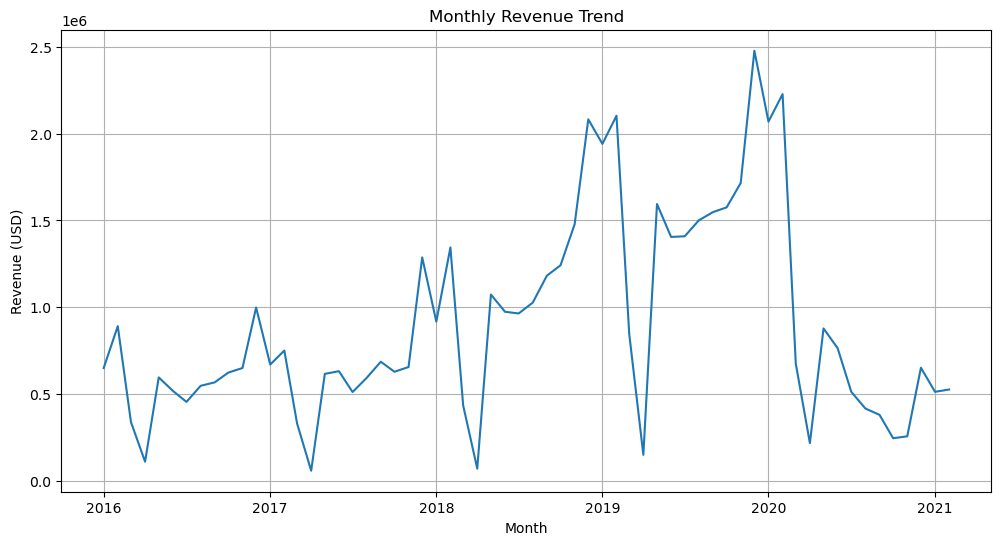

In [647]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["Year-Month"],
    monthly_revenue["Revenue USD"]
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.grid(True)

plt.show()

In [649]:
#One-time vs Repeat Customer Revenue.
customer_type_revenue = (
    customer_behavior
    .groupby("Customer Type")["Revenue USD"]
    .sum()
)

customer_type_revenue

Customer Type
One-time     9819402.20
Repeat      45936077.39
Name: Revenue USD, dtype: float64

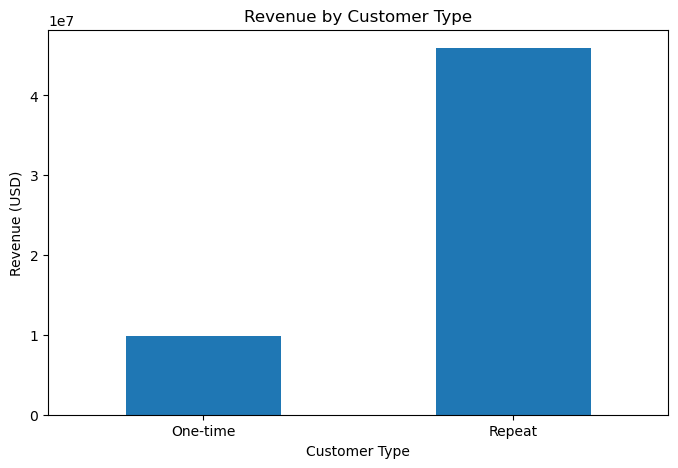

In [651]:
#Revenue by Customer Type

plt.figure(figsize=(8, 5))

customer_type_revenue.plot(kind="bar")

plt.title("Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=0)

plt.show()

In [653]:
# Physical Store Revenue per Store by Country
# Exclude online sales to analyze physical-store productivity.

physical_sales = sales_analysis[
    sales_analysis["Store Country"] != "Online"
]

In [655]:
#now we are calculating total revenue and number of stores for each country.

country_store_performance = (
    physical_sales
    .groupby("Store Country")
    .agg(
        Total_Revenue=("Revenue USD", "sum"),
        Number_of_Stores=("StoreKey", "nunique")
    )
    .reset_index()
)

country_store_performance["Revenue_per_Store"] = (
    country_store_performance["Total_Revenue"]
    / country_store_performance["Number_of_Stores"]
)

country_store_performance = country_store_performance.sort_values(
    "Revenue_per_Store",
    ascending=False
)

country_store_performance.round(2)

,Store Country,Total_Revenue,Number_of_Stores,Revenue_per_Store
1,Canada,3611561.79,3,1203853.93
7,United States,23764425.86,20,1188221.29
6,United Kingdom,5749769.78,7,821395.68
4,Italy,2059086.81,3,686362.27
3,Germany,4246279.22,8,530784.90
0,Australia,2099141.07,5,419828.21
5,Netherlands,1591344.48,4,397836.12
2,France,1229545.95,7,175649.42


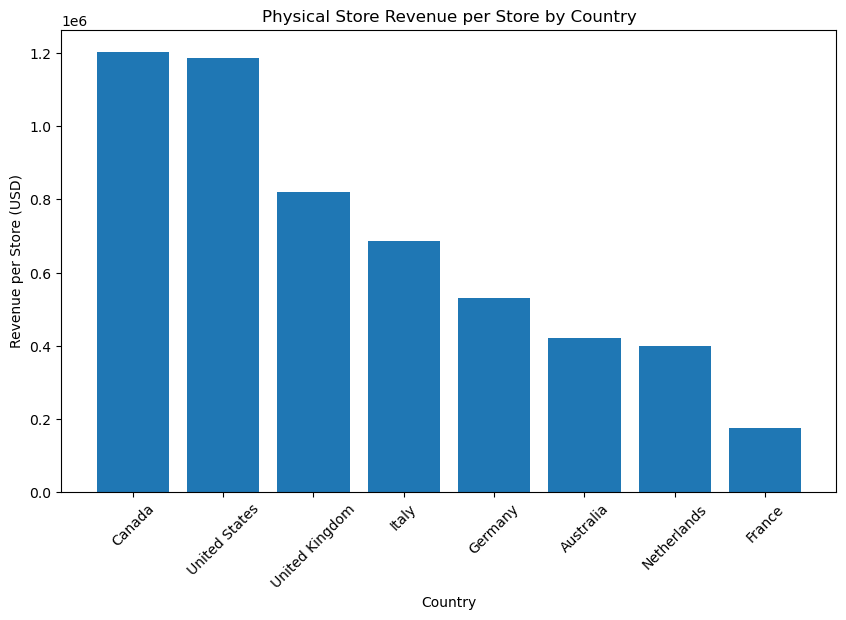

In [657]:
plt.figure(figsize=(10, 6))

plt.bar(
    country_store_performance["Store Country"],
    country_store_performance["Revenue_per_Store"]
)

plt.title("Physical Store Revenue per Store by Country")
plt.xlabel("Country")
plt.ylabel("Revenue per Store (USD)")
plt.xticks(rotation=45)

plt.show()

###Insights

Although the United States generated the highest total physical-store revenue, Canada had the highest revenue per store at approximately $1.20M, 
slightly ahead of the United States at $1.19M.

This demonstrates that total revenue alone does not fully reflect store productivity. Normalizing revenue by the number of stores provides a more
meaningful comparison across countries with different store counts.

## Python Analysis Summary

Python was used to clean, validate, integrate, and analyze the retail datasets after the initial SQL analysis.

### Key Findings

- **Overall Performance:** The dataset generated approximately **$55.76M in revenue**, **$23.09M in cost**, and **$32.66M in gross profit**, with a **58.58% gross margin**. Python results matched the SQL calculations.

- **Customer Revenue Concentration:** The highest-spending **20% of purchasing customers generated approximately 55% of total revenue**, indicating moderate customer revenue concentration rather than a strict 80/20 pattern.

- **Repeat Customer Value:** Repeat customers represented **61.18% of purchasing customers** but generated **82.39% of total revenue**. Their higher total customer value was primarily driven by purchasing more frequently rather than having a substantially higher average order value.

- **Product Price vs. Sales Volume:** Product price had only a **weak negative correlation (-0.13)** with quantity sold, suggesting that price alone does not strongly explain product sales volume.

- **Revenue Trend:** Revenue generally increased through 2018–2019, with strong monthly performance continuing into early 2020 before declining substantially during the remainder of 2020. The 2021 data is incomplete and extends only through February 20, so it should not be treated as a full-year comparison.

- **Category and Product Performance:** Computers generated the highest overall revenue and gross profit, while Music, Movies and Audio Books had the highest gross margin. No category's leading product contributed more than approximately 7% of category revenue, suggesting category revenue was distributed across multiple products.

- **Store Productivity:** The United States generated the highest total physical-store revenue, but Canada ranked highest after normalizing revenue by store count, generating approximately **$1.20M per store**, compared with **$1.19M per store** in the United States.

### Conclusion

The analysis shows that repeat purchasing behavior is a major revenue driver, product price has limited association with sales volume, and normalized store-level metrics can reveal insights that are not visible from total revenue alone.